# EDA — Give Me Some Credit + simulated behavioral features

Short exploration to motivate the modelling choices:
1. How dirty is the raw data (missing values, sentinel codes, outliers)?
2. How big is the **thin-file** segment and how risky is it?
3. Do the **simulated** behavioral features carry a mild (not overwhelming) signal?

> The behavioral features are synthetic — see `src/simulate.py`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # run from notebooks/

import matplotlib.pyplot as plt
import pandas as pd
from src.config import BEHAVIORAL_FEATURES, TARGET, THIN_FILE_MAX_OPEN_LINES
from src.data import load_raw, clean
from src.features import thin_file_mask
from src.simulate import simulate_behavioral

raw = load_raw()
print(raw.shape)
raw.head()

(150000, 11)


,serious_dlq_2yrs,revolving_utilization,age,past_due_30_59,debt_ratio,monthly_income,open_credit_lines,past_due_90_plus,real_estate_loans,past_due_60_89,dependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 1. Data quality

In [2]:
quality = pd.DataFrame({
    "missing_%": raw.isna().mean().mul(100).round(2),
    "max": raw.max(),
    "p99": raw.quantile(0.99),
})
quality

,missing_%,max,p99
serious_dlq_2yrs,0.00,1.0,1.000000
revolving_utilization,0.00,50708.0,1.092956
age,0.00,109.0,87.000000
past_due_30_59,0.00,98.0,4.000000
debt_ratio,0.00,329664.0,4979.040000
monthly_income,19.82,3008750.0,25000.000000
open_credit_lines,0.00,58.0,24.000000
past_due_90_plus,0.00,98.0,3.000000
real_estate_loans,0.00,54.0,4.000000
past_due_60_89,0.00,98.0,2.000000


In [3]:
# Past-due counts of 96/98 are sentinel codes, not real counts
sentinel = raw["past_due_30_59"].isin([96, 98])
print(f"sentinel rows: {sentinel.sum()} | default rate among them: {raw.loc[sentinel, TARGET].mean():.1%}")
print(f"overall default rate: {raw[TARGET].mean():.2%}")

sentinel rows: 269 | default rate among them: 54.6%
overall default rate: 6.68%


Sentinel rows default far more than average, so `src/data.py` maps them to the cap ("many late payments") instead of dropping them. Utilisation and debt ratio have extreme tails, hence the fixed caps.

## 2. Thin-file segment

In [4]:
df = simulate_behavioral(clean(raw))
thin = thin_file_mask(df)
print(f"thin-file (<= {THIN_FILE_MAX_OPEN_LINES} open lines): {thin.mean():.1%} of applicants")
df.groupby(df["open_credit_lines"].clip(upper=15))[TARGET].agg(["mean", "size"]).rename(
    columns={"mean": "default_rate", "size": "n"}).T.round(3)

thin-file (<= 2 open lines): 8.7% of applicants


open_credit_lines,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
default_rate,0.256,0.132,0.091,0.075,0.064,0.063,0.055,0.056,0.048,0.058,0.06,0.057,0.063,0.055,0.066,0.071
n,1888.000,4438.000,6666.000,9058.000,11609.000,12931.000,13613.000,13245.000,12562.000,11355.000,9624.00,8321.000,7005.000,5667.000,4546.000,17471.000


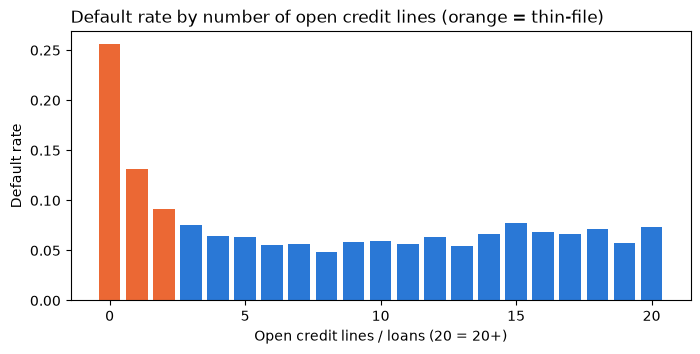

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
rate = df.groupby(df["open_credit_lines"].clip(upper=20))[TARGET].mean()
ax.bar(rate.index, rate.values, color=["#eb6834" if i <= THIN_FILE_MAX_OPEN_LINES else "#2a78d6" for i in rate.index])
ax.set_xlabel("Open credit lines / loans (20 = 20+)"); ax.set_ylabel("Default rate")
ax.set_title("Default rate by number of open credit lines (orange = thin-file)", loc="left")
plt.show()

Thin-file applicants are both rarer and riskier — and the bureau has less information to separate good from bad among them. That is exactly where additional data should help most.

## 3. Simulated behavioral features

In [6]:
df.groupby(TARGET)[BEHAVIORAL_FEATURES].mean().T.round(2)

serious_dlq_2yrs,0,1
on_time_payment_streak,15.60,10.11
avg_daily_km_driven,42.27,47.72
active_driving_days_per_month,24.32,21.43
late_night_driving_ratio,0.11,0.16
device_tamper_alerts,0.10,0.21


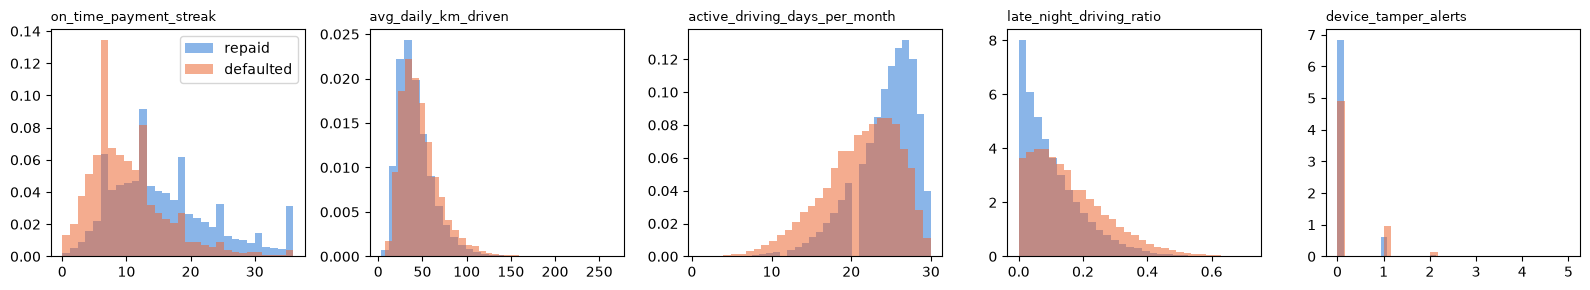

In [7]:
fig, axes = plt.subplots(1, len(BEHAVIORAL_FEATURES), figsize=(16, 3))
for ax, col in zip(axes, BEHAVIORAL_FEATURES):
    for y, color, label in ((0, "#2a78d6", "repaid"), (1, "#eb6834", "defaulted")):
        ax.hist(df.loc[df[TARGET] == y, col], bins=30, density=True, alpha=0.55, color=color, label=label)
    ax.set_title(col, fontsize=9, loc="left")
axes[0].legend()
plt.tight_layout(); plt.show()

Distributions overlap heavily: each feature shifts only slightly between classes, by design. Any lift comes from combining several weak signals, not from a leaked label.